# Project Larissa: walkthrough

This notebook reproduces the Larissa demo's detection results from the released
**Larissa-Synth v1** dataset (`data/larissa_synth_v1`) and the trained 3D Gaussian
Splatting baseline that ships with it. It does not retrain the baseline (that
takes about 36 minutes on a Tesla P40; run `run_demo.py` for the full pipeline).

Steps:
1. look at the data;
2. load the baseline and check its rendering quality on held-out views;
3. calibrate the alarm levels on healthy held-out views;
4. run detection and classification on the five inspection scenarios;
5. compare with `results/summary.json` from the original run.

In [1]:
import json, sys, time
from pathlib import Path
import torch, matplotlib.pyplot as plt
sys.path.insert(0, "..")
from larissa.dataset import LarissaSynth
from larissa.gaussians import GaussianModel, render, psnr
from larissa.detect import calibrate_threshold, calibrate_components, detect, classify_components, verdict

dev = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("device:", dev, torch.cuda.get_device_name(0) if dev.type == "cuda" else "")
data = LarissaSynth("../data/larissa_synth_v1")
print("scenarios:", data.scenarios)
print("components:", data.components)
print(len(data.meta["train"]), "training views,", len(data.meta["holdout"]), "held-out views,",
      len(data.meta["inspection"]["healthy_control"]["views"]), "inspection cameras per scenario")

device: cuda:0 Tesla P40
scenarios: ['healthy_control', 'panel_hinge', 'antenna_missing', 'mli_discoloration', 'sun_shift_control']
components: {0: 'background', 1: 'bus', 2: 'solar_array_port', 3: 'solar_array_starboard', 4: 'antenna', 5: 'thruster'}
96 training views, 12 held-out views, 8 inspection cameras per scenario


## 1. The data
A few healthy baseline captures, then the same inspection camera in every scenario.

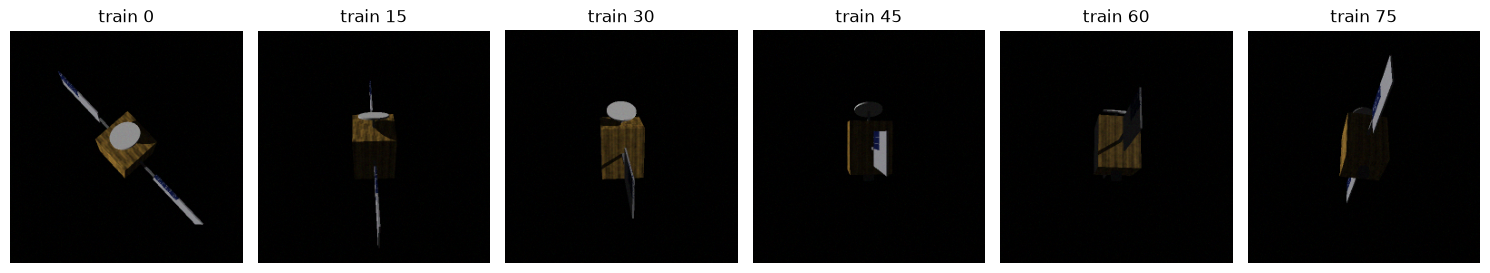

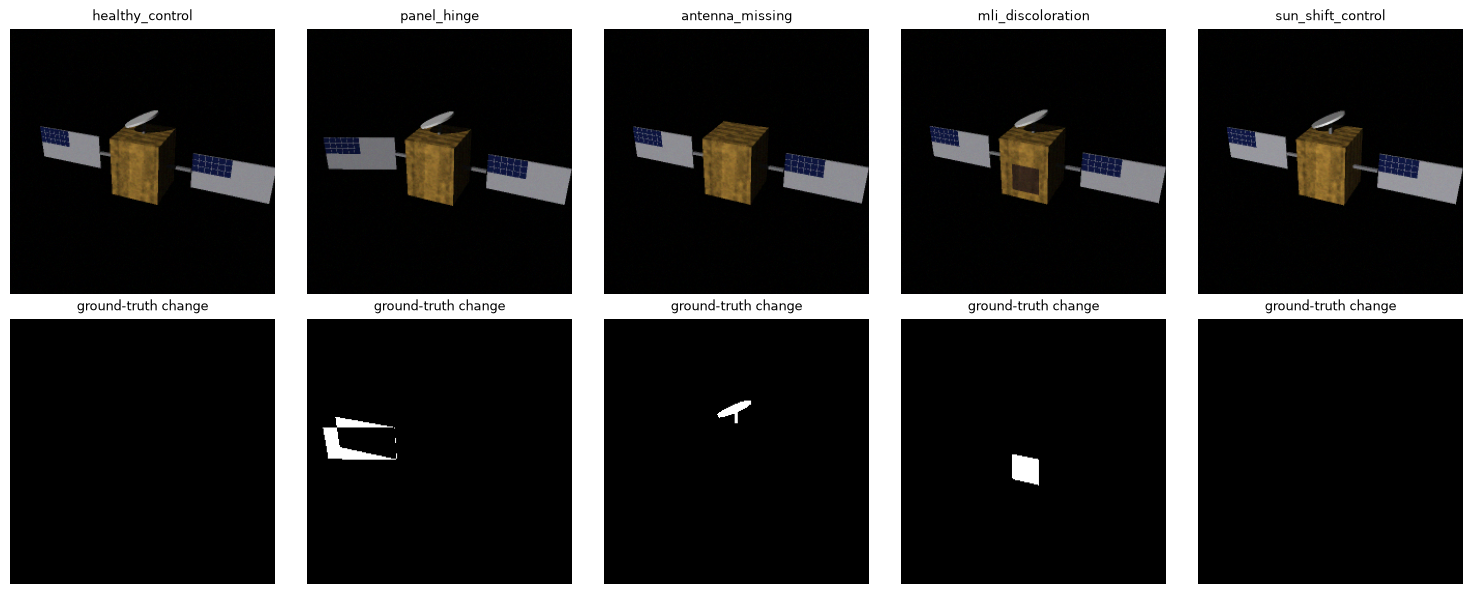

In [2]:
fig, ax = plt.subplots(1, 6, figsize=(15, 2.8))
for k, i in enumerate([0, 15, 30, 45, 60, 75]):
    ax[k].imshow(data.train_view(i)["rgb"]); ax[k].set_title(f"train {i}"); ax[k].axis("off")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(2, 5, figsize=(15, 6))
for k, s in enumerate(data.scenarios):
    imgs, cams, gts = data.inspection(s)
    ax[0, k].imshow(imgs[2]); ax[0, k].set_title(s, fontsize=9); ax[0, k].axis("off")
    ax[1, k].imshow(gts[2], cmap="gray"); ax[1, k].set_title("ground-truth change", fontsize=9); ax[1, k].axis("off")
plt.tight_layout(); plt.show()

## 2. The baseline
Rendering the trained Gaussians at held-out camera poses (which carry a small pose error, as in operations).

/tmp/ipykernel_622651/2782893172.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model = GaussianModel.from_state_dict(torch.load("../data/larissa_synth_v1/baseline_gaus

43929 Gaussians; per-component counts: {'bus': 22952, 'solar_array_port': 8979, 'solar_array_starboard': 9362, 'antenna': 2002, 'thruster': 634}


mean PSNR vs noisy held-out captures: 35.61 dB


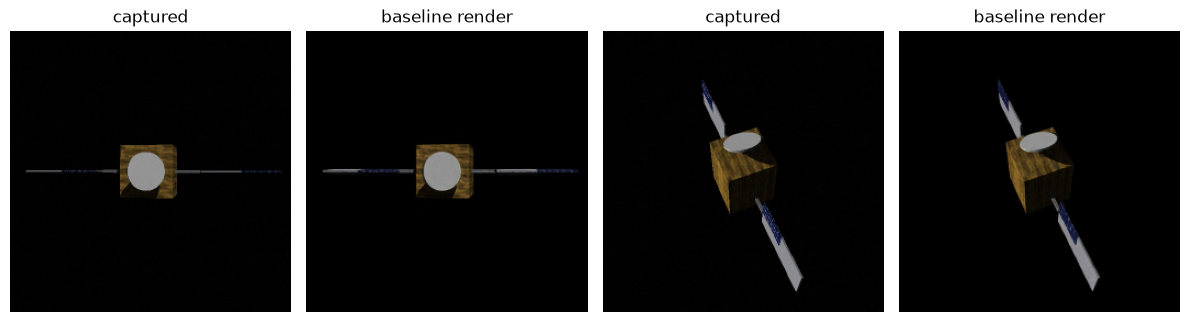

In [3]:
model = GaussianModel.from_state_dict(torch.load("../data/larissa_synth_v1/baseline_gaussians.pt"), dev)
print(len(model), "Gaussians; per-component counts:",
      {data.components[int(c)]: int((model.comp == c).sum()) for c in model.comp.unique()})
hold_imgs, hold_cams = data.holdout()
hold_imgs = [im.to(dev) for im in hold_imgs]
with torch.no_grad():
    rends = [render(model, c)["rgb"].clamp(0, 1) for c in hold_cams]
print("mean PSNR vs noisy held-out captures: %.2f dB" % (sum(psnr(r, g) for r, g in zip(rends, hold_imgs)) / len(rends)))
fig, ax = plt.subplots(1, 4, figsize=(12, 3.2))
for k in range(2):
    ax[2*k].imshow(hold_imgs[k].cpu()); ax[2*k].set_title("captured"); ax[2*k].axis("off")
    ax[2*k+1].imshow(rends[k].cpu()); ax[2*k+1].set_title("baseline render"); ax[2*k+1].axis("off")
plt.tight_layout(); plt.show()

## 3. Calibration on healthy data only
The pixel threshold is the 99.5th percentile of the healthy difference map; each component's alarm level is set from how much of it the healthy views flag.

In [4]:
tau = calibrate_threshold(model, hold_imgs, hold_cams)
comp_thr = calibrate_components(model, hold_imgs, hold_cams, tau)
print("tau = %.4f" % tau)
print({k: round(v, 4) for k, v in comp_thr.items()})

tau = 0.0400
{'bus': 0.02, 'solar_array_port': 0.0202, 'solar_array_starboard': 0.02, 'antenna': 0.2169, 'thruster': 0.02}


## 4. Inspection passes

In [5]:
rows, dets = [], {}
for s in data.scenarios:
    imgs, cams, gts = data.inspection(s)
    imgs = [im.to(dev) for im in imgs]
    t0 = time.time()
    det = detect(model, imgs, cams, tau, comp_thresholds=comp_thr)
    cls = classify_components(model, imgs, cams, det, log=lambda *a: None)
    v = verdict(cls)
    dets[s] = (det, imgs, gts)
    changed = {k: f"{c['flagged']}/{c['evaluated']}" for k, c in det.components.items() if c["changed"]}
    rows.append((s, v, changed, round(time.time() - t0, 2)))
    print(f"{s:20s} {v}\n{'':20s} changed components: {changed}  ({rows[-1][3]} s)")

healthy_control      NO CHANGE
                     changed components: {}  (0.53 s)


panel_hinge          GEOMETRIC CHANGE: solar_array_port
                     changed components: {'solar_array_port': '8114/8977'}  (0.81 s)


antenna_missing      GEOMETRIC CHANGE: antenna
                     changed components: {'bus': '927/19943', 'antenna': '1956/1956'}  (1.04 s)


mli_discoloration    APPEARANCE CHANGE: bus
                     changed components: {'bus': '2182/19943'}  (0.74 s)


sun_shift_control    APPEARANCE CHANGE ON MANY PARTS (likely illumination): bus, solar_array_port, antenna
                     changed components: {'bus': '8990/19943', 'solar_array_port': '717/8977', 'antenna': '1458/1956'}  (1.33 s)


## 5. Agreement with the original run

In [6]:
orig = {r["scenario"]: r for r in json.load(open("../results/summary.json"))["scenarios"]}
for s, v, changed, _ in rows:
    o = orig[s]
    print(f"{s:20s} verdict matches original: {v == o['verdict']}   expected: {o['expected']:11s} correct: {o['correct']}")

healthy_control      verdict matches original: True   expected: NO CHANGE   correct: True
panel_hinge          verdict matches original: True   expected: GEOMETRIC   correct: True
antenna_missing      verdict matches original: True   expected: GEOMETRIC   correct: True
mli_discoloration    verdict matches original: True   expected: APPEARANCE  correct: True
sun_shift_control    verdict matches original: True   expected: NO FAULT    correct: True


## 6. A closer look
Pixel-level change before voting (red), ground truth (cyan), for the camera with the most change.

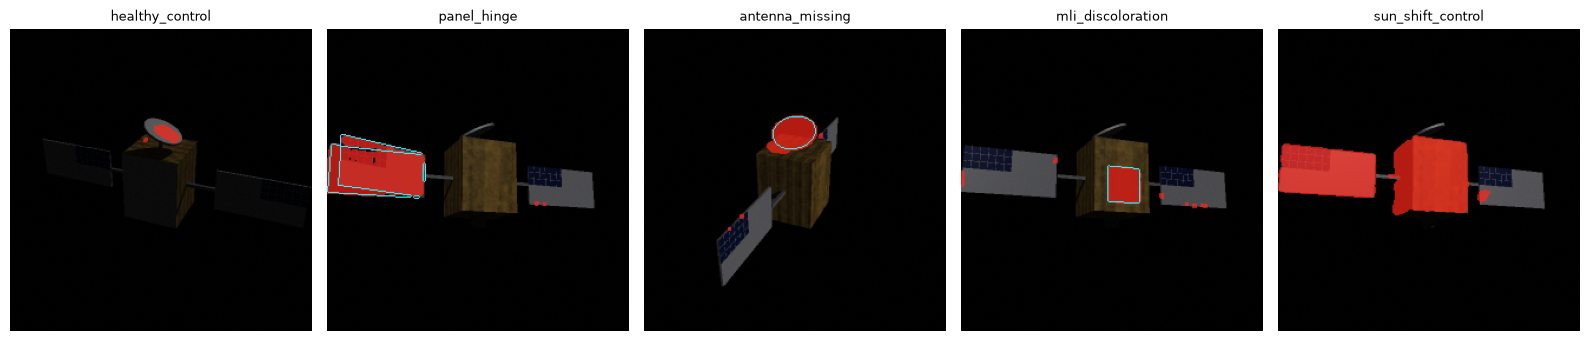

In [7]:
from scipy.ndimage import binary_dilation
import numpy as np
fig, ax = plt.subplots(1, 5, figsize=(16, 3.4))
for k, s in enumerate(data.scenarios):
    det, imgs, gts = dets[s]
    i = int(np.argmax([m.sum() for m in det.masks]))
    over = imgs[i].cpu().numpy() * 0.55
    m = det.masks[i].numpy(); g = gts[i].numpy()
    over[m] = over[m] * 0.3 + np.array([1, .15, .1]) * 0.7
    over[binary_dilation(g) & ~g] = [0.2, 0.95, 1.0]
    ax[k].imshow(over.clip(0, 1)); ax[k].set_title(s, fontsize=9); ax[k].axis("off")
plt.tight_layout(); plt.show()

## Notes
* The Sun-shift control is expected to fail: the baseline was captured under one Sun angle,
  so moved shadows and glints look like moved hardware. See the README and the paper.
* Detection thresholds were tuned on these same scenarios; treat the results as a
  feasibility demonstration, not an accuracy claim.